<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/4.%20Replication%20Run%20(WBS%3A%203.4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4 Replication Run

The two baselines of Wang and Hasuike (2026) on the project's data, for every λ in the paper's grid, on both universes, over the test months, set against Table 3:

- **Plain PTO**: ridge regression forecasts passed to the optimizer;
- **Classic Markowitz**: historical average returns passed to the same optimizer.

The paper finds that plain PTO trades far more than classic Markowitz and that raising λ does not change this. Section 8 tests this with four criteria fixed before the run.

**Inputs:** Daily Prices, Monthly Data, Daily Features, Daily Training Windows, Covariances

**Outputs** (`data` folder):

| File | Folder | Contents |
|---|---|---|
| PTO Forecasts.parquet | processed | Forecast return of each ETF at each decision date, with the chosen ridge penalty |
| Replication Months.parquet | processed | Monthly returns, fee and turnover of every run |
| Replication Results.csv | reports | Performance of every run next to the paper's values, over 81 and 70 months |
| Replication Checks.csv | reports | Results of all checks, including the pass criteria |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: aaa5ba3, Backtest Engine (2026-10-30 15:39)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import backtest, cleaning, config, forecast, variables

# Reload after a fresh clone
for module in (config, cleaning, variables, backtest, forecast):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 160)

# All check reports of the notebook, saved together at the end
checks = []

## 2. Load the inputs

Only the 9+3 window of Wang and Hasuike is used.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

# Decision calendar, holding-month returns, sample covariances and historical means
calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}

assert (pd.DatetimeIndex(calendar["decision_date"]) == returns["ETF_A"].index).all()
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")
print(f"Classic Markowitz averages the last {config.MU_DAYS} trading days")

81 decision dates, 2020-01 to 2026-09
Classic Markowitz averages the last 126 trading days


## 3. Forecasts

At each decision date, one ridge regression per universe is fitted on the daily rows of the 9+3 window and predicts each ETF's return over the coming month.

- **Inputs:** the seven features, standardized on the fitted rows, plus a 0/1 column per ticker;
- **Target:** the 21-day forward return;
- **Penalty:** one of 15 values from 0.1 to 10⁶, chosen by squared error on the 3-month validation slice, fitting only rows whose returns are known before validation starts. The chosen model is refitted on the whole window.

A large penalty pulls every forecast toward the window's average return; a small one lets the features and tickers separate the ETFs.

In [4]:
fc = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u)) for u in universes],
               ignore_index=True)
per_month = fc.drop_duplicates(["universe", "date"])
print(f"{len(fc):,} forecasts, {per_month['fit_rows'].median():.0f} fit rows and "
      f"{per_month['validation_rows'].median():.0f} validation rows in a typical month")
print()
print("Chosen ridge penalty (share of months)")
print(per_month.groupby("universe")["alpha"].value_counts(normalize=True).unstack(0).fillna(0).round(2).to_string())

1,458 forecasts, 1504 fit rows and 560 validation rows in a typical month

Chosen ridge penalty (share of months)
universe   ETF_A  ETF_B
alpha                  
0.1         0.11   0.04
10.0        0.00   0.02
31.6        0.02   0.00
100.0       0.02   0.09
316.0       0.05   0.02
1000.0      0.09   0.10
3160.0      0.15   0.16
10000.0     0.06   0.05
31600.0     0.02   0.02
100000.0    0.02   0.05
316000.0    0.00   0.01
1000000.0   0.44   0.43


## 4. Checks on the forecasts

Every month has a forecast for every ETF, no training return is known later than its decision date, and three random months refitted with scikit-learn's `Ridge` give the same forecasts.

In [5]:
for u in universes:
    report = forecast.check_forecasts(fc, daily_table, calendar, u, backtest.tickers_of(u))
    print(u)
    print(report.to_string(index=False))
    print()
    checks.append(report.assign(table=f"PTO Forecasts {u}"))
fc_columns = variables.check_table(fc, "PTO Forecasts")
checks.append(fc_columns.assign(table="PTO Forecasts"))
print("Column checks:", fc_columns["status"].value_counts().to_dict())
if (pd.concat(checks)["status"] == "FAIL").any():
    raise RuntimeError("A forecast check failed.")

ETF_A
               check status                                                               detail
            complete   PASS                              81 months x 8 ETFs, no missing forecast
       no look-ahead   PASS                  every training target is known on its decision date
matches scikit-learn   PASS 3 random months refit with sklearn Ridge, largest difference 6.8e-17

ETF_B
               check status                                                               detail
            complete   PASS                             81 months x 10 ETFs, no missing forecast
       no look-ahead   PASS                  every training target is known on its decision date
matches scikit-learn   PASS 3 random months refit with sklearn Ridge, largest difference 5.9e-17

Column checks: {'PASS': 10}


## 5. Forecast quality

| Measure | Meaning |
|---|---|
| Out-of-sample R² | 1 − squared forecast error relative to a forecast of zero |
| Mean IC | Average monthly rank correlation between forecasts and realized returns across ETFs |
| IC t-statistic | Mean IC divided by its standard error over the months |
| Top pick beats average | Share of months in which the ETF with the highest forecast beat the universe average; 0.5 is chance |
| Spread ratio | Cross-sectional spread of forecasts divided by that of realized returns |

The chart shows the average forecast across ETFs against the average realized return each month, the view of the paper's Figure 1.

          oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
universe                                                                  
ETF_A     -0.040    0.039       0.74                   0.519         0.155
ETF_B     -0.044   -0.051      -1.03                   0.407         0.151


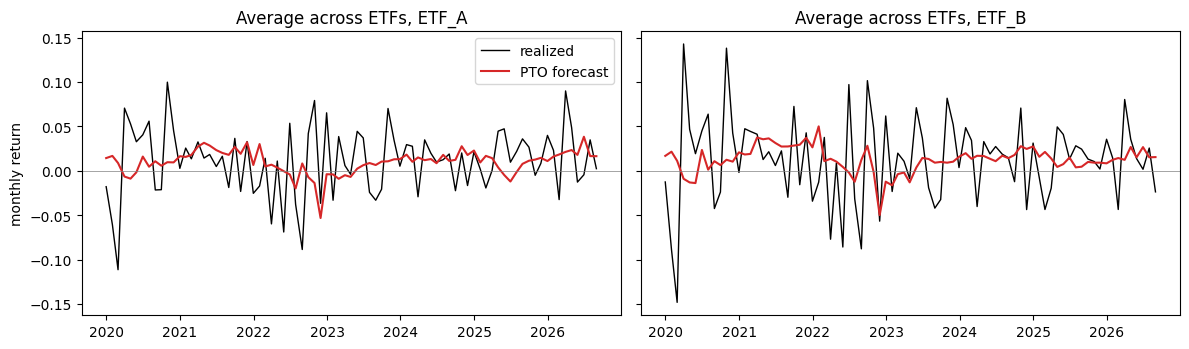

In [6]:
quality = forecast.forecast_quality(fc, panel)
print(quality.round(3).to_string())

# Average forecast and realized return across ETFs, each month
realized = panel[["date", "universe", "ticker", "next_return"]]
m = fc.merge(realized, on=["date", "universe", "ticker"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, u in zip(axes, universes):
    g = m[m["universe"] == u].groupby("date")[["forecast", "next_return"]].mean()
    ax.plot(g.index, g["next_return"], color="black", lw=1, label="realized")
    ax.plot(g.index, g["forecast"], color="tab:red", lw=1.5, label="PTO forecast")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"Average across ETFs, {u}")
axes[0].set_ylabel("monthly return")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Replication run

Both strategies use the same optimizer, the sample covariance, κ = 0.005, a start from equal weights and the 0.5% fee; they differ only in the expected returns. Every month of every run is recomputed independently.

In [7]:
mu_pto = {u: fc[fc["universe"] == u].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
          for u in universes}
runs, weights_by_run = [], {}
for u in universes:
    for name, mu in (("Plain PTO", mu_pto[u]), ("Classic Markowitz", hist_mu[u])):
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov_sample[u], lam), returns[u])
            report = backtest.check_accounting(mo, w, returns[u])
            checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
            runs.append(mo.assign(strategy=name, universe=u, lam=lam))
            weights_by_run[(name, u, lam)] = w

rep_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if c["table"].iloc[0].startswith("Backtest")])
print(f"{rep_months.groupby(['strategy', 'universe', 'lam']).ngroups} runs; "
      f"accounting checks: {len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed")
rm_columns = variables.check_table(rep_months, "Replication Months")
checks.append(rm_columns.assign(table="Replication Months"))
print("Column checks:", rm_columns["status"].value_counts().to_dict())
if (acc["status"] == "FAIL").any() or (rm_columns["status"] == "FAIL").any():
    raise RuntimeError("A backtest check failed.")

20 runs; accounting checks: 100 run, 0 failed
Column checks: {'PASS': 12}


## 7. Results next to Table 3

The paper's turnover figures point to a test of about 70 months, so the comparison covers the first 70 test months (to October 2025). The full 81 months are saved alongside.

First 70 months
                                 turnover  paper_turnover  ann_vol  paper_ann_vol  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown  effective_n
strategy          universe lam                                                                                                                        
Classic Markowitz ETF_A    0.1      0.170           0.194    0.196          0.248   0.717         0.654        -0.198              -0.312        1.004
                           1.0      0.180           0.248    0.178          0.236   0.780         0.440        -0.170              -0.312        1.324
                           10.0     0.127           0.142    0.097          0.108   0.519         0.285        -0.144              -0.213        2.136
                           20.0     0.081           0.091    0.072          0.078   0.392         0.248        -0.125              -0.170        2.019
                           50.0     0.046           0.045    0.061          0.

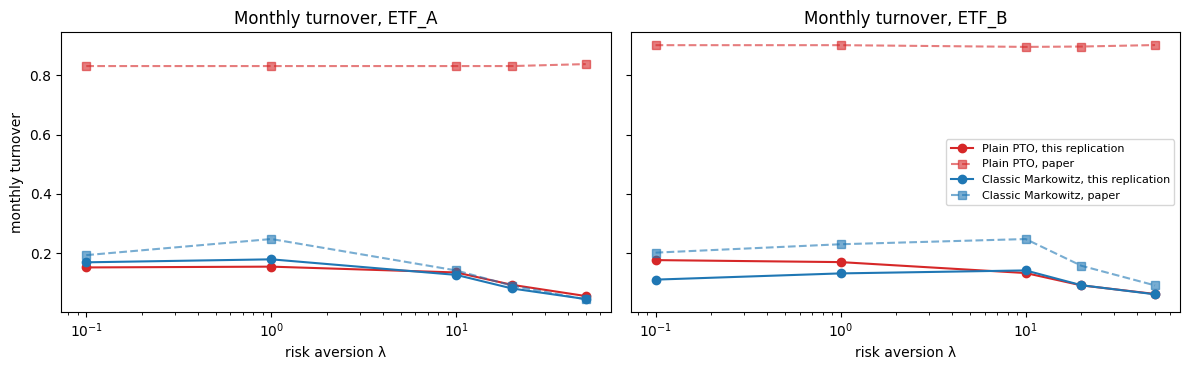

In [8]:
def summarize(rows):
    """Performance metrics of every run in `rows`, one row per strategy, universe and λ."""
    return pd.DataFrame([backtest.metrics(g).rename((s, u, l))
                         for (s, u, l), g in rows.groupby(["strategy", "universe", "lam"])])


metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
paper = pd.concat([backtest.paper_rows("PTO").assign(strategy="Plain PTO"),
                   backtest.paper_rows("MVO").assign(strategy="Classic Markowitz")]
                  ).set_index(["strategy", "universe", "lam"])


def side_by_side(table):
    """Metrics of each run joined with the paper's values for the same strategy, universe and λ."""
    out = table[metric_names + ["effective_n"]].copy()
    out.index.names = ["strategy", "universe", "lam"]
    return out.join(paper.add_prefix("paper_"))


full = summarize(rep_months)
first70 = summarize(rep_months[rep_months["month"] <= config.PAPER_LAST_MONTH])
comparison70 = side_by_side(first70)
cols = ["turnover", "paper_turnover", "ann_vol", "paper_ann_vol", "sharpe", "paper_sharpe",
        "max_drawdown", "paper_max_drawdown", "effective_n"]
print("First 70 months")
print(comparison70[cols].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, u in zip(axes, universes):
    for name, color in (("Plain PTO", "tab:red"), ("Classic Markowitz", "tab:blue")):
        s = comparison70.loc[(name, u)]
        ax.plot(s.index, s["turnover"], "o-", color=color, label=f"{name}, this replication")
        ax.plot(s.index, s["paper_turnover"], "s--", color=color, alpha=0.6, label=f"{name}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Monthly turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Pass criteria

On ETF_A over the first 70 months:

1. Plain PTO turnover is at least 0.6 at every λ and changes by less than 0.1 between λ = 0.1 and λ = 50.
2. Plain PTO turnover is at least three times classic Markowitz turnover at every λ from 10 up.
3. Classic Markowitz volatility falls at each step of the λ grid, and its turnover is below 0.3 at every λ.
4. Classic Markowitz volatility at λ = 10, 20 and 50 is within 30% of the paper's value.

Criteria 1 and 2 test the paper's finding; criteria 3 and 4 confirm that the optimizer and covariance are on the paper's scale. Results are reported as they stand.

In [9]:
pto = comparison70.loc[("Plain PTO", "ETF_A")].sort_index()
mvo = comparison70.loc[("Classic Markowitz", "ETF_A")].sort_index()
hi = [l for l in config.LAMBDA_GRID if l >= 10]
ratio = pto.loc[hi, "turnover"] / mvo.loc[hi, "turnover"]
vol_gap = (mvo.loc[hi, "ann_vol"] / mvo.loc[hi, "paper_ann_vol"] - 1).abs()
change = abs(pto.loc[50.0, "turnover"] - pto.loc[0.1, "turnover"])
criteria = pd.DataFrame([
    {"check": "1. PTO trades heavily at every λ",
     "status": "PASS" if (pto["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
     "detail": f"turnover {pto['turnover'].min():.3f} to {pto['turnover'].max():.3f}; "
               f"change from λ = 0.1 to 50: {change:.3f}"},
    {"check": "2. PTO trades 3x Markowitz at λ ≥ 10",
     "status": "PASS" if (ratio >= 3).all() else "FAIL",
     "detail": "ratios " + ", ".join(f"{r:.1f}" for r in ratio)},
    {"check": "3. Markowitz volatility falls, turnover < 0.3",
     "status": "PASS" if (mvo["ann_vol"].diff().dropna() < 0).all() and (mvo["turnover"] < 0.3).all() else "FAIL",
     "detail": "volatility " + ", ".join(f"{v:.3f}" for v in mvo["ann_vol"])
               + f"; turnover up to {mvo['turnover'].max():.3f}"},
    {"check": "4. Markowitz volatility within 30% of paper",
     "status": "PASS" if (vol_gap <= 0.3).all() else "FAIL",
     "detail": "gaps " + ", ".join(f"{g:.0%}" for g in vol_gap) + " at λ = 10, 20, 50"},
])
print(criteria.to_string(index=False))
checks.append(criteria.assign(table="Pass criteria"))

                                        check status                                                             detail
             1. PTO trades heavily at every λ   FAIL          turnover 0.056 to 0.155; change from λ = 0.1 to 50: 0.096
         2. PTO trades 3x Markowitz at λ ≥ 10   FAIL                                               ratios 1.1, 1.2, 1.2
3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.196, 0.178, 0.097, 0.072, 0.061; turnover up to 0.180
  4. Markowitz volatility within 30% of paper   PASS                                 gaps 10%, 8%, 7% at λ = 10, 20, 50


## 9. Portfolio holdings

Target weights of both strategies on ETF_A at λ = 20, month by month, and the share of months in which a single ETF holds more than 90% of the portfolio (first 70 months).

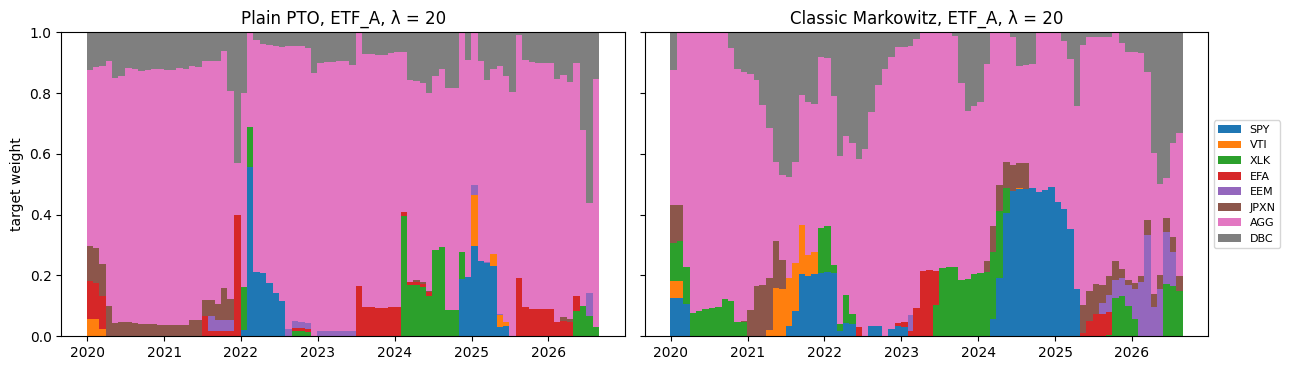

lam                         0.1   1.0   10.0  20.0  50.0
strategy          universe                              
Classic Markowitz ETF_A     0.99  0.61  0.00  0.10  0.17
                  ETF_B     0.83  0.60  0.00  0.00  0.00
Plain PTO         ETF_A     0.73  0.47  0.06  0.06  0.04
                  ETF_B     0.66  0.29  0.13  0.00  0.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
colors = plt.cm.tab10(np.arange(len(config.ETF_A)))
for ax, name in zip(axes, ("Plain PTO", "Classic Markowitz")):
    w = weights_by_run[(name, "ETF_A", 20.0)].pivot(index="date", columns="ticker", values="target")[config.ETF_A]
    ax.stackplot(w.index, w.T.to_numpy(), labels=config.ETF_A, colors=colors, step="post")
    ax.set_title(f"{name}, ETF_A, λ = 20")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("target weight")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

# Share of months with one ETF above 90%
single = []
for (name, u, lam), w in weights_by_run.items():
    top = w.groupby("date")["target"].max()
    top = top[top.index <= pd.Timestamp(config.PAPER_LAST_MONTH) - pd.offsets.MonthEnd(1)]
    single.append({"strategy": name, "universe": u, "lam": lam, "one ETF above 90%": (top > 0.9).mean()})
print(pd.DataFrame(single).pivot_table(index=["strategy", "universe"], columns="lam",
                                       values="one ETF above 90%").round(2).to_string())

## 10. Save

In [11]:
fc.to_parquet(proc / config.FILES["forecasts"], index=False)
rep_months.to_parquet(proc / config.FILES["replication_months"], index=False)
results = pd.concat([side_by_side(full).assign(window="81 months"), comparison70.assign(window="70 months")])
results.reset_index().to_csv(DIRS["reports"] / config.FILES["replication_results"], index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / config.FILES["replication_checks"], index=False)

## 11. Summary

In [12]:
# Key figures
passed = int((all_checks["status"] == "PASS").sum())
failed = int((all_checks["status"] == "FAIL").sum())
a = comparison70.xs("ETF_A", level="universe")
print(f"Forecasts:      {len(fc):,} ({len(calendar)} months, both universes)")
print(f"ETF_A, 70 months, plain PTO turnover:        {a.loc['Plain PTO', 'turnover'].min():.2f} to "
      f"{a.loc['Plain PTO', 'turnover'].max():.2f} (paper {a.loc['Plain PTO', 'paper_turnover'].min():.2f} to "
      f"{a.loc['Plain PTO', 'paper_turnover'].max():.2f})")
print(f"ETF_A, 70 months, classic Markowitz turnover: {a.loc['Classic Markowitz', 'turnover'].min():.2f} to "
      f"{a.loc['Classic Markowitz', 'turnover'].max():.2f} (paper {a.loc['Classic Markowitz', 'paper_turnover'].min():.2f} to "
      f"{a.loc['Classic Markowitz', 'paper_turnover'].max():.2f})")
print(f"Pass criteria:  {', '.join(criteria['status'])}")
print(f"Checks:         {passed} passed, {failed} failed")

Forecasts:      1,458 (81 months, both universes)
ETF_A, 70 months, plain PTO turnover:        0.06 to 0.16 (paper 0.83 to 0.84)
ETF_A, 70 months, classic Markowitz turnover: 0.05 to 0.18 (paper 0.04 to 0.25)
Pass criteria:  FAIL, FAIL, PASS, PASS
Checks:         130 passed, 2 failed
